# 01 — Exploratory data analysis

**P03: Hotel-booking cancellations and the overbooking decision**

Phase A notebook: load and inspect the raw data, explore required cancellation patterns, audit leakage, and document cleaning decisions. This notebook does not train a model or change the raw CSV.

Before running, put the original `hotel_bookings.csv` in `data/raw/`. Run this notebook from the project copy. Expected data size from the brief: 119,390 rows × 32 columns.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving hotel_bookings.csv to hotel_bookings.csv


In [4]:
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
DATA_PATH = Path("/content/hotel_bookings.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}. Download hotel_bookings.csv and place it in data/raw/.")
df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH.resolve()}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded /content/hotel_bookings.csv
Shape: 119,390 rows × 32 columns


## 1. First look and data checks

Check the preview, columns, data types, missingness, duplicate rows, and target values. Differences from the expected dimensions are reported for investigation rather than silently corrected.

In [5]:
display(df.head())
display(df.dtypes.astype(str).rename("dtype").to_frame().join(df.isna().sum().rename("missing")))
display(df.describe(include="all").T)
print("Duplicate rows:", int(df.duplicated().sum()))
print("Target values:", sorted(df["is_canceled"].dropna().unique().tolist()))
required = {"is_canceled", "hotel", "lead_time", "deposit_type", "market_segment", "previous_cancellations"}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns missing: {sorted(missing_columns)}")
if df.shape != (119390, 32):
    warnings.warn(f"Observed shape {df.shape}; the brief expects (119390, 32). Check the downloaded file/version.")

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,dtype,missing
hotel,object,0
is_canceled,int64,0
lead_time,int64,0
arrival_date_year,int64,0
arrival_date_month,object,0
arrival_date_week_number,int64,0
arrival_date_day_of_month,int64,0
stays_in_weekend_nights,int64,0
stays_in_week_nights,int64,0
adults,int64,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


Duplicate rows: 31994
Target values: [0, 1]


## 2. Cancellation balance overall and by hotel

Show counts and rates. These are descriptive associations, not evidence that a booking characteristic causes cancellation.

In [ ]:
overall = df["is_canceled"].value_counts(dropna=False).rename_axis("is_canceled").to_frame("bookings")
overall["share"] = overall["bookings"] / len(df)
display(overall)
print(f"Overall cancellation rate: {df['is_canceled'].mean():.1%}")
by_hotel = df.groupby("hotel", dropna=False)["is_canceled"].agg(bookings="size", cancellations="sum", cancellation_rate="mean")
display(by_hotel)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="is_canceled", ax=axes[0], color="steelblue")
axes[0].set(title="Bookings by cancellation outcome", xlabel="is_canceled (0 = no, 1 = yes)", ylabel="Bookings")
sns.barplot(data=by_hotel.reset_index(), x="hotel", y="cancellation_rate", ax=axes[1], color="darkorange")
axes[1].set(title="Cancellation rate by hotel", xlabel="Hotel", ylabel="Cancellation rate", ylim=(0, 1))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.tight_layout(); plt.show()

## 3. Cancellation patterns and `Non Refund` investigation

Lead time is grouped only for the chart. Tables include group sizes because rates based on very small groups can be unstable. Explain the unusually high `Non Refund` rate using the observed counts and context; do not claim causation.


Cancellation summary by lead_time_group


,bookings,cancellations,cancellation_rate
lead_time_group,,,
366+ days,3148,2130,0.676620
181–365,21544,11947,0.554540
91–180,26439,11821,0.447105
31–90,29553,11141,0.376984
8–30,18960,5283,0.278639
0–7,19746,1902,0.096323



Cancellation summary by deposit_type


,bookings,cancellations,cancellation_rate
deposit_type,,,
Non Refund,14587,14494,0.993624
No Deposit,104641,29694,0.283770
Refundable,162,36,0.222222



Cancellation summary by market_segment


,bookings,cancellations,cancellation_rate
market_segment,,,
Undefined,2,2,1.000000
Groups,19811,12097,0.610620
Online TA,56477,20739,0.367211
Offline TA/TO,24219,8311,0.343160
Aviation,237,52,0.219409
Corporate,5295,992,0.187347
Direct,12606,1934,0.153419
Complementary,743,97,0.130552



Cancellation summary by previous_cancellations


,bookings,cancellations,cancellation_rate
previous_cancellations,,,
24,48,48,1.000000
26,26,26,1.000000
25,25,25,1.000000
21,1,1,1.000000
19,19,19,1.000000
14,14,14,1.000000
1,6051,5714,0.944307
13,12,11,0.916667
0,112906,38282,0.339061


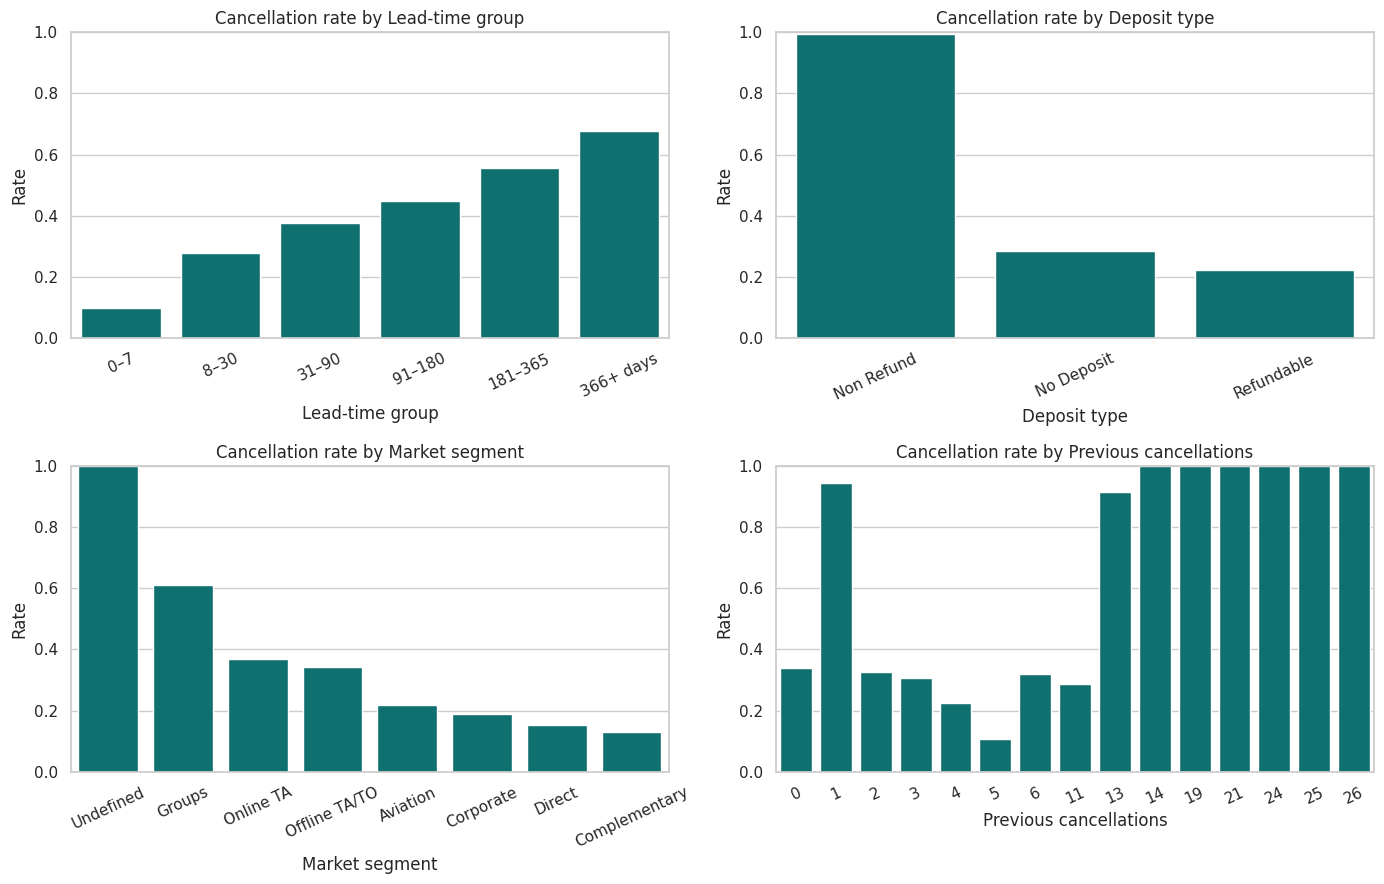

,bookings,cancellations,cancellation_rate
deposit_type,,,
Non Refund,14587,14494,0.993624
No Deposit,104641,29694,0.283770
Refundable,162,36,0.222222


Non Refund: 14,587 bookings, 14,494 cancellations, rate 99.4%


In [6]:
eda = df[["is_canceled", "lead_time", "deposit_type", "market_segment", "previous_cancellations"]].copy()
eda["lead_time_group"] = pd.cut(eda["lead_time"], [-1, 7, 30, 90, 180, 365, float("inf")], labels=["0–7", "8–30", "31–90", "91–180", "181–365", "366+ days"])
def cancellation_summary(column):
    return eda.groupby(column, dropna=False, observed=False)["is_canceled"].agg(bookings="size", cancellations="sum", cancellation_rate="mean").sort_values("cancellation_rate", ascending=False)

for col in ["lead_time_group", "deposit_type", "market_segment", "previous_cancellations"]:
    print(f"\nCancellation summary by {col}")
    display(cancellation_summary(col))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col, title in zip(axes.flat, ["lead_time_group", "deposit_type", "market_segment", "previous_cancellations"], ["Lead-time group", "Deposit type", "Market segment", "Previous cancellations"]):
    summary = cancellation_summary(col).reset_index()
    sns.barplot(data=summary, x=col, y="cancellation_rate", ax=ax, color="teal")
    ax.set(title=f"Cancellation rate by {title}", xlabel=title, ylabel="Rate", ylim=(0, 1))
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

deposit_summary = cancellation_summary("deposit_type")
display(deposit_summary)
if "Non Refund" in deposit_summary.index:
    row = deposit_summary.loc["Non Refund"]
    print(f"Non Refund: {int(row['bookings']):,} bookings, {int(row['cancellations']):,} cancellations, rate {row['cancellation_rate']:.1%}")
else:
    print("No exact 'Non Refund' category found; inspect deposit_type values.")

**Interpretation — complete after running:** Compare `Non Refund` with the other deposit groups, mention its sample size, and give a cautious explanation. `[Write your interpretation here.]`

## 4. Leakage audit

A feature must be available when a reservation is made. The brief identifies these suspect columns. `reservation_status` directly reveals the outcome and must never be used as a predictor. Verify these against the downloaded data and add every further excluded field and reason here and in the README.

In [7]:
leakage_audit = pd.DataFrame([
    {"column": "reservation_status", "decision": "Drop", "reason": "Directly records the outcome (Canceled / Check-Out / No-Show)."},
    {"column": "reservation_status_date", "decision": "Drop", "reason": "Date the status was set; reflects events after booking."},
    {"column": "assigned_room_type", "decision": "Drop", "reason": "Room is assigned at check-in, not reservation time."},
    {"column": "days_in_waiting_list", "decision": "Exclude pending timing audit", "reason": "Waiting-list resolution may accrue after the booking."},
    {"column": "booking_changes", "decision": "Drop", "reason": "Counts changes made after the initial reservation."},
])
leakage_audit["present_in_data"] = leakage_audit["column"].isin(df.columns)
display(leakage_audit)
print("All source columns for timing review:")
display(pd.DataFrame({"column": df.columns}))

,column,decision,reason,present_in_data
0,reservation_status,Drop,Directly records the outcome (Canceled / Check...,True
1,reservation_status_date,Drop,Date the status was set; reflects events after...,True
2,assigned_room_type,Drop,"Room is assigned at check-in, not reservation ...",True
3,days_in_waiting_list,Exclude pending timing audit,Waiting-list resolution may accrue after the b...,True
4,booking_changes,Drop,Counts changes made after the initial reservat...,True


All source columns for timing review:


,column
0,hotel
1,is_canceled
2,lead_time
3,arrival_date_year
4,arrival_date_month
5,arrival_date_week_number
6,arrival_date_day_of_month
7,stays_in_weekend_nights
8,stays_in_week_nights
9,adults


## 5. Missing values, zero-guest rows, and ADR outliers

The brief notes 4 missing `children`, about 488 missing `country`, and missing `agent`/`company` meaning none. Confirm the counts in this file. Do not edit the raw CSV. Use the decision log after examining the counts and ADR distribution; justify each choice.

,count,percent
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


children: 4 missing (0.00%)
country: 488 missing (0.41%)
agent: 16,340 missing (13.69%)
company: 112,593 missing (94.31%)
Rows with zero adults, children, and babies: 180


,hotel,adults,children,babies,is_canceled
2224,Resort Hotel,0,0.0,0,0
2409,Resort Hotel,0,0.0,0,0
3181,Resort Hotel,0,0.0,0,0
3684,Resort Hotel,0,0.0,0,0
3708,Resort Hotel,0,0.0,0,0
4127,Resort Hotel,0,0.0,0,1
9376,Resort Hotel,0,0.0,0,1
31765,Resort Hotel,0,0.0,0,0
32029,Resort Hotel,0,0.0,0,0
32827,Resort Hotel,0,0.0,0,0


ADR > 5000: 1
ADR above Q3 + 3×IQR (296.13): 327


,adr
count,119390.000000
mean,101.831122
std,50.535790
min,-6.380000
50%,94.575000
90%,164.000000
95%,193.500000
99%,252.000000
99.9%,326.201630
max,5400.000000


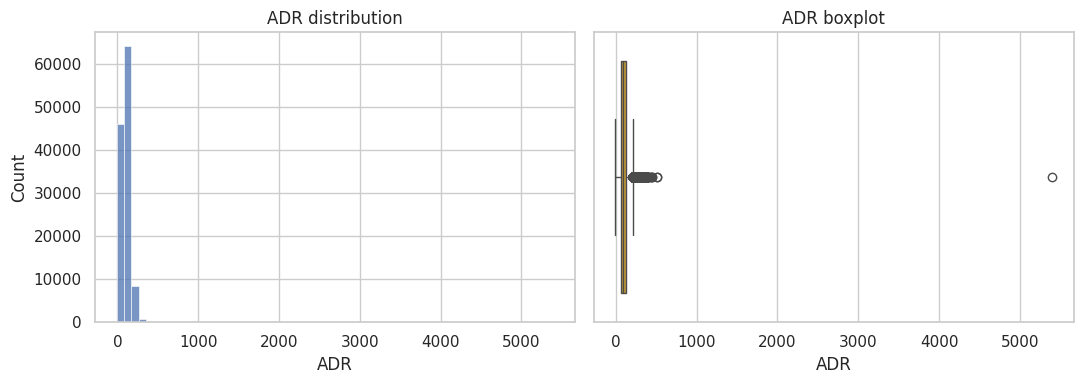

In [8]:
missing = pd.DataFrame({"count": df.isna().sum(), "percent": df.isna().mean().mul(100)}).query("count > 0").sort_values("count", ascending=False)
display(missing)
for col in ["children", "country", "agent", "company"]:
    if col in df.columns:
        print(f"{col}: {df[col].isna().sum():,} missing ({df[col].isna().mean():.2%})")

guest_cols = ["adults", "children", "babies"]
zero_guest_mask = df[guest_cols].fillna(0).sum(axis=1).eq(0)
print(f"Rows with zero adults, children, and babies: {zero_guest_mask.sum():,}")
display(df.loc[zero_guest_mask, ["hotel", *guest_cols, "is_canceled"]].head(10))

q1, q3 = df["adr"].quantile([.25, .75])
upper_fence = q3 + 3 * (q3 - q1)
print(f"ADR > 5000: {(df['adr'] > 5000).sum():,}")
print(f"ADR above Q3 + 3×IQR ({upper_fence:.2f}): {(df['adr'] > upper_fence).sum():,}")
display(df["adr"].describe(percentiles=[.5, .9, .95, .99, .999]).to_frame())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["adr"], bins=60, ax=axes[0]); axes[0].set(title="ADR distribution", xlabel="ADR")
sns.boxplot(x=df["adr"], ax=axes[1], color="goldenrod"); axes[1].set(title="ADR boxplot", xlabel="ADR")
plt.tight_layout(); plt.show()

### Cleaning decision log — complete as a group

Fill in a specific treatment and one-line reason for each issue. Check ADR extremes rather than removing them automatically: an extreme value may be an error or a valid observation. Carry the agreed decisions into the preprocessing notebook and summarize them in the README.

In [9]:
cleaning_log = pd.DataFrame([
    {"issue": "Missing children", "observed count": int(df["children"].isna().sum()), "decision": "[fill in]", "reason": "[fill in]"},
    {"issue": "Missing country", "observed count": int(df["country"].isna().sum()), "decision": "[fill in]", "reason": "[fill in]"},
    {"issue": "Missing agent (means none)", "observed count": int(df["agent"].isna().sum()), "decision": "[fill in]", "reason": "[fill in]"},
    {"issue": "Missing company (means none)", "observed count": int(df["company"].isna().sum()), "decision": "[fill in]", "reason": "[fill in]"},
    {"issue": "Zero-guest rows", "observed count": int(zero_guest_mask.sum()), "decision": "[fill in]", "reason": "[fill in]"},
    {"issue": "ADR outliers", "observed count": int((df["adr"] > 5000).sum()), "decision": "[fill in]", "reason": "[fill in]"},
])
display(cleaning_log)

,issue,observed count,decision,reason
0,Missing children,4,[fill in],[fill in]
1,Missing country,488,[fill in],[fill in]
2,Missing agent (means none),16340,[fill in],[fill in]
3,Missing company (means none),112593,[fill in],[fill in]
4,Zero-guest rows,180,[fill in],[fill in]
5,ADR outliers,1,[fill in],[fill in]


## Phase A completion checklist

- [ ] Raw CSV loaded; notebook shows shape and a preview.
- [ ] Cancellation balance shown overall and for each hotel.
- [ ] Cancellation rates examined against lead time, deposit type, market segment, and previous cancellations.
- [ ] `Non Refund` group investigated with its count and rate, then interpreted cautiously.
- [ ] Leakage audit completed and copied into the README.
- [ ] Missing values, zero-guest rows, and ADR outliers have documented cleaning decisions.

Run all cells and save the notebook with outputs before using it as checkpoint evidence. The baseline model and metric are for the later checkpoint; do not invent a result here.